In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
# load the csv
df = pd.read_csv("data/battery_data.csv")

arr = df.to_numpy()
hours_arr = arr[:,0].astype(float)
life_arr = arr[:,1].astype(float)

<function matplotlib.pyplot.show(close=None, block=None)>

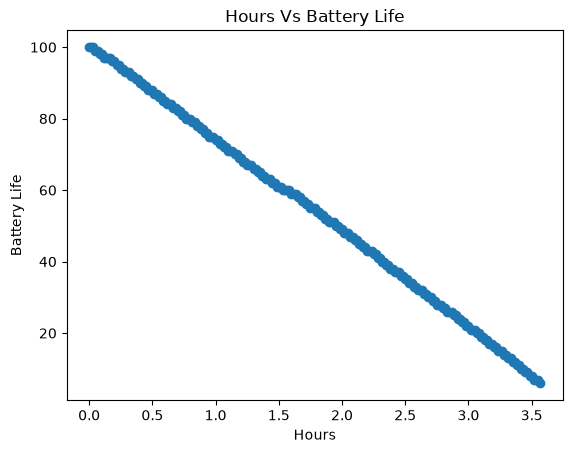

In [3]:
plt.scatter(hours_arr, life_arr)
plt.title("Hours Vs Battery Life")
plt.xlabel("Hours")
plt.ylabel("Battery Life")
plt.show

In [4]:
# cost calculation

def cost(x_i: np.ndarray, y_i: np.ndarray, w: float, b: float) -> float:    
    f_wb = w * x_i + b
    sum = (f_wb - y_i) ** 2
    sum = np.sum(sum)
    cost = sum / (2 * len(x_i))
    return cost

In [5]:
def gradient(x_i: np.ndarray, y_i: np.ndarray, w: float, b: float) -> tuple:
    f_wb = w * x_i + b
    sum_b = f_wb - y_i
    sum_w = sum_b * x_i
    sum_w = np.sum(sum_w)
    sum_b = np.sum(sum_b)

    grad_w = sum_w / (len(x_i))
    grad_b = sum_b / (len(x_i))
    return grad_w, grad_b

In [6]:
# change w and b simultaneously until we done

def lin_regression(x_i: np.ndarray, y_i: np.ndarray, alpha: float, cost, gradient) -> tuple:
    costs = []
    parameters = []
    w = 0
    b = 0
    prev_cost = 0
    curr_cost = cost(x_i, y_i, w, b)
    iters = 0
    while (abs(prev_cost - curr_cost) > 0.0000001):
        prev_cost = curr_cost
        grad_w, grad_b = gradient(x_i, y_i, w, b)
        w = w - alpha * grad_w
        b = b - alpha * grad_b
        curr_cost = cost(x_i, y_i, w, b)
        costs.append(curr_cost)
        parameters.append([w, b])
        if iters % 50 == 0:
            print(f"iter: {iters} w: {w} b: {b} cost: {curr_cost}")
        iters += 1            
    return w, b, costs, parameters

In [7]:
w_final, b_final, costs, parameters = lin_regression(hours_arr, life_arr, 0.1, cost, gradient)
print(w_final, b_final)

iter: 0 w: 6.792861723396915 b: 5.386976744186047 cost: 1247.3564579426888
iter: 50 w: -12.402758576059107 b: 69.30548725715606 cost: 125.77798823796591
iter: 100 w: -21.54876457273072 b: 90.01461390883452 cost: 14.81203772984265
iter: 150 w: -24.67529862357281 b: 97.09396523040996 cost: 1.8446319895484975
iter: 200 w: -25.74409468325531 b: 99.51401972991879 cost: 0.32926974677561505
iter: 250 w: -26.109459332613632 b: 100.34130792548316 cost: 0.15218554251677543
iter: 300 w: -26.23435811549312 b: 100.62411385347329 cost: 0.13149160247204386
iter: 350 w: -26.277054380696054 b: 100.72079019109684 cost: 0.1290733226691261
iter: 400 w: -26.291649967780657 b: 100.75383870009634 cost: 0.12879072413097684
iter: 450 w: -26.296639424383752 b: 100.76513623136346 cost: 0.1287576998574131
-26.297392801413793 100.76684208857996


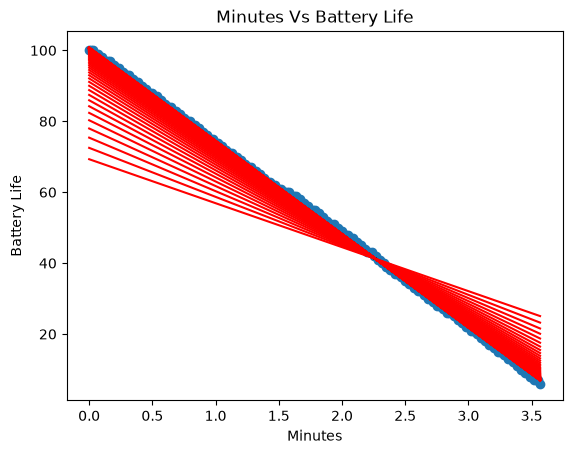

In [8]:
plt.scatter(hours_arr, life_arr)
for i in range(50, 400, 5):
    plt.plot(hours_arr, parameters[i][0]*hours_arr + parameters[i][1], color="red", label="model")
plt.title("Minutes Vs Battery Life")
plt.xlabel("Minutes")
plt.ylabel("Battery Life")
plt.show()